# V59 — Una sola red también para el tubo: la red en cadena ordinal da las láminas enteras de cada capa

**Qué cambia respecto de V47.** En V47 la red de pared gruesa era un perceptrón común que daba espesores reales y servía solo como
punto de partida. En V59 se usa **la misma red del primer nivel (Figura 3 del artículo): la red en cadena con salida ordinal**.
Recibe la curva presión–diámetro λ(P) del paciente y da **directamente las láminas enteras de cada capa** (0 a 20) y el
preestiramiento δ. Después se puede afinar δ (una sola variable) y revisar ±1 lámina por material.

**Referencia.** El procedimiento de 3 pasos de V47 (arranque de pared delgada → mínimos cuadrados no lineales de pared gruesa →
minimax entero), que se llama aquí *minimax* para abreviar.

**Tope de 20 láminas por material** (criterio de fabricación). Para respetarlo con láminas de 0,025 mm, la rigidez de los
materiales más rígidos se recalibró: con 6 materiales, ×1,111, ×1,278 y ×1,5 para los materiales 4, 5 y 6; con 5, ×1,5 el 5.


In [1]:
# CELDA 0: CONFIGURACIÓN (ejecutar siempre primero)
#   V59 = la red en cadena ORDINAL del primer nivel, llevada al tubo de pared gruesa: da directamente las láminas enteras
#   de cada capa (0 a 20) y el preestiramiento δ. Se compara contra el procedimiento de 3 pasos de V47 (el «minimax»).
#   V47 = un solo procedimiento en 3 pasos (arranque → MCO no lineal, que ajusta y suaviza → láminas enteras con minimax contra la
#   curva del ajuste) y DOS caminos que solo difieren en el arranque: A) sin red (MCO lineal de pared delgada), B) con red.
#   V46 = V45 con TRES caminos al diseño ENTERO, comparados contra la curva original de pared gruesa:
#     1) minimax no lineal directo → láminas · 2) mínimos cuadrados no lineales → láminas · 3) red → minimax no lineal → láminas.
#   V45 = V44 con láminas de 0,025 mm (adoptado). V44 = V43 + diseño por el criterio del PEOR PUNTO (minimax no lineal) y paso a LÁMINAS ENTERAS de espesor fijo.
#   (La red y las etiquetas son las de V43: la red sigue siendo el punto de partida.)
#   V43: PARED GRUESA con geometría documentada y presiones fisiológicas. Cada arteria (y cada injerto) se describe por su curva
#   diámetro–presión: λθ(P), el estiramiento circunferencial en r_m para P de 60 a 200 mmHg (la misma ventana para todos).
#   El injerto es un tubo de capas (una por material); cada material es una RECTA TRUNCADA σ = E·max(0, λ − κ).
#   El aporte de cada capa depende de dónde está en la pared → el problema espesores → curva es NO lineal.
import os
import numpy as np

N_BASES = 5                      # ← número de materiales: 5 o 6
VERSION = f"v59_{N_BASES}"
SEED = 42
DIR_MASSON = "."
ENTRENAR = "auto"                # "auto": carga la red si sus archivos están; si no, la entrena

# Ventana de presión (igual para todos los sujetos) y conversión
MMHG = 0.133322                  # kPa por mmHg
P_MIN_MMHG, P_MAX_MMHG, N_P = 60.0, 200.0, 141
P_GRID = np.linspace(P_MIN_MMHG, P_MAX_MMHG, N_P) * MMHG          # [kPa]
P_REF_KPA = 13.332               # escala adimensional de la presión: P/P_ref, con P_ref = 13,332 kPa (= 100 mmHg)
P_REF_MMHG = P_REF_KPA / MMHG
X_FINO = np.linspace(0.98, 1.40, 841)                               # λθ donde se calcula P(λ) antes de invertir

# Geometría documentada
#   R_m, Θ0, λz: Masson et al. (2011), Tablas 2 y 4 (por sujeto).
#   Espesor de la pared (íntima–media) h: mediana de referencia del IMT de carótida común por edad y sexo,
#   Engelen et al. (2013), Eur Heart J 34:2368–2380, Tabla 3 (ecotracking, el mismo tipo de equipo que Masson).
IMT_ENGELEN = {"M": (15, 401.0, 26.2), "F": (15, 396.0, 24.9)}       # (edad 15 años, mediana a esa edad [µm], aumento cada 5 años [µm])
N_RADIAL = 60

# Materiales: nudos y módulos de las bases de V41 (rectas truncadas). E_j = PEND_MAX_j [kPa por unidad de λ]
MATERIALES = {6: dict(nudos=[0.8193, 1.0227, 1.0774, 1.1099, 1.1318, 1.1478], E=[246.3, 827.8, 694.6, 1155.7, 1664.6, 2222.6]),
              5: dict(nudos=[0.8228, 1.0243, 1.0881, 1.1226, 1.1447], E=[251.1, 871.4, 1038.3, 1774.8, 2581.5])}
H_CAPA_MAX = 3.0                 # cota física de búsqueda de una capa [mm] (no es una restricción de diseño)
N_GAUSS_CAPA = 8

ERROR_MAX_PCT = 3.0
ESP_LAMINA_MM = 0.025               # ← espesor de una lámina [mm]: cada capa = n láminas enteras (n ≥ 0)
FRAC_SUJETOS_TEST = 0.25
ETQ_P, ETQ_L = "P [kPa]", r"$\lambda_\theta$ (en $r_m$)"

_v = VERSION
ARCHIVO_MODELO, ARCHIVO_SCALERS, ARCHIVO_HISTORIAL = (f"modelo_rn_{_v}.keras", f"scalers_{_v}.pkl", f"historial_entrenamiento_{_v}.csv")
ARCHIVO_ETIQUETAS = f"etiquetas_pared_gruesa_{_v}.npz"
if ENTRENAR == "auto":
    ENTRENAR = not all(os.path.exists(f) for f in (ARCHIVO_MODELO, ARCHIVO_SCALERS, ARCHIVO_HISTORIAL))
print(f"✅ {VERSION} | {N_BASES} materiales | pared gruesa | curva λθ(P) para P de {P_MIN_MMHG:g} a {P_MAX_MMHG:g} mmHg | "
      f"red: {'se entrena' if ENTRENAR else 'se carga de ' + ARCHIVO_MODELO}")
# --- V59 ---------------------------------------------------------------------------------------------------------------
TOPE_LAMINAS = 20                # a lo sumo 20 láminas por material (criterio de fabricación)
E_ESCALA = {6: [1, 1, 1, 1.111, 1.278, 1.5], 5: [1, 1, 1, 1, 1.5]}[N_BASES]   # recalibración de la rigidez para respetar el tope
ARCHIVO_MODELO = f"modelo_rn_cadena_tubo_{VERSION}.weights.h5"
ARCHIVO_SCALERS = f"scalers_cadena_tubo_{VERSION}.pkl"
ARCHIVO_HISTORIAL = f"historial_entrenamiento_cadena_tubo_{VERSION}.csv"
ARCHIVO_ETIQUETAS = f"etiquetas_enteras_tubo_{VERSION}.npz"
ENTRENAR = not all(os.path.exists(f) for f in (ARCHIVO_MODELO, ARCHIVO_SCALERS, ARCHIVO_HISTORIAL))
print(f"   V59: red en cadena ordinal para el tubo | tope {TOPE_LAMINAS} láminas por material | rigidez ×{E_ESCALA} | "
      f"red: {'se entrena' if ENTRENAR else 'se carga'}")


✅ v59_5 | 5 materiales | pared gruesa | curva λθ(P) para P de 60 a 200 mmHg | red: se entrena
   V59: red en cadena ordinal para el tubo | tope 20 láminas por material | rigidez ×[1, 1, 1, 1, 1.5] | red: se carga


## Celda 1 — Los 41 sujetos

✅ 41 sujetos | espesor (IMT, Engelen 2013): 0.426–0.684 mm (mediana 0.610) | λθ en 60 mmHg: 1.019–1.166 | en 200 mmHg: 1.122–1.225
   test: NT02, NT08, NT10, NT11, HT03, HT05, HT13, HT14, HT19, HT24
  id  age gender  Rm_mm  h_mm  lambda_60  lambda_200
NT01   62      F  4.261 0.630      1.090       1.157
NT02   60      M  4.691 0.637      1.096       1.176
NT03   31      M  4.305 0.485      1.115       1.202
NT04   31      M  4.672 0.485      1.142       1.225
NT05   34      F  4.203 0.491      1.080       1.179
NT06   53      F  3.957 0.585      1.081       1.161
NT07   21      F  3.827 0.426      1.081       1.184
NT08   25      M  4.856 0.453      1.166       1.214
NT09   42      F  4.506 0.530      1.088       1.166
NT10   55      M  4.770 0.611      1.054       1.133
NT11   64      M  5.566 0.658      1.060       1.134
NT12   60      F  4.876 0.620      1.097       1.169
NT13   61      F  4.924 0.625      1.087       1.167
NT14   39      F  3.539 0.516      1.085       1.167
NT15  

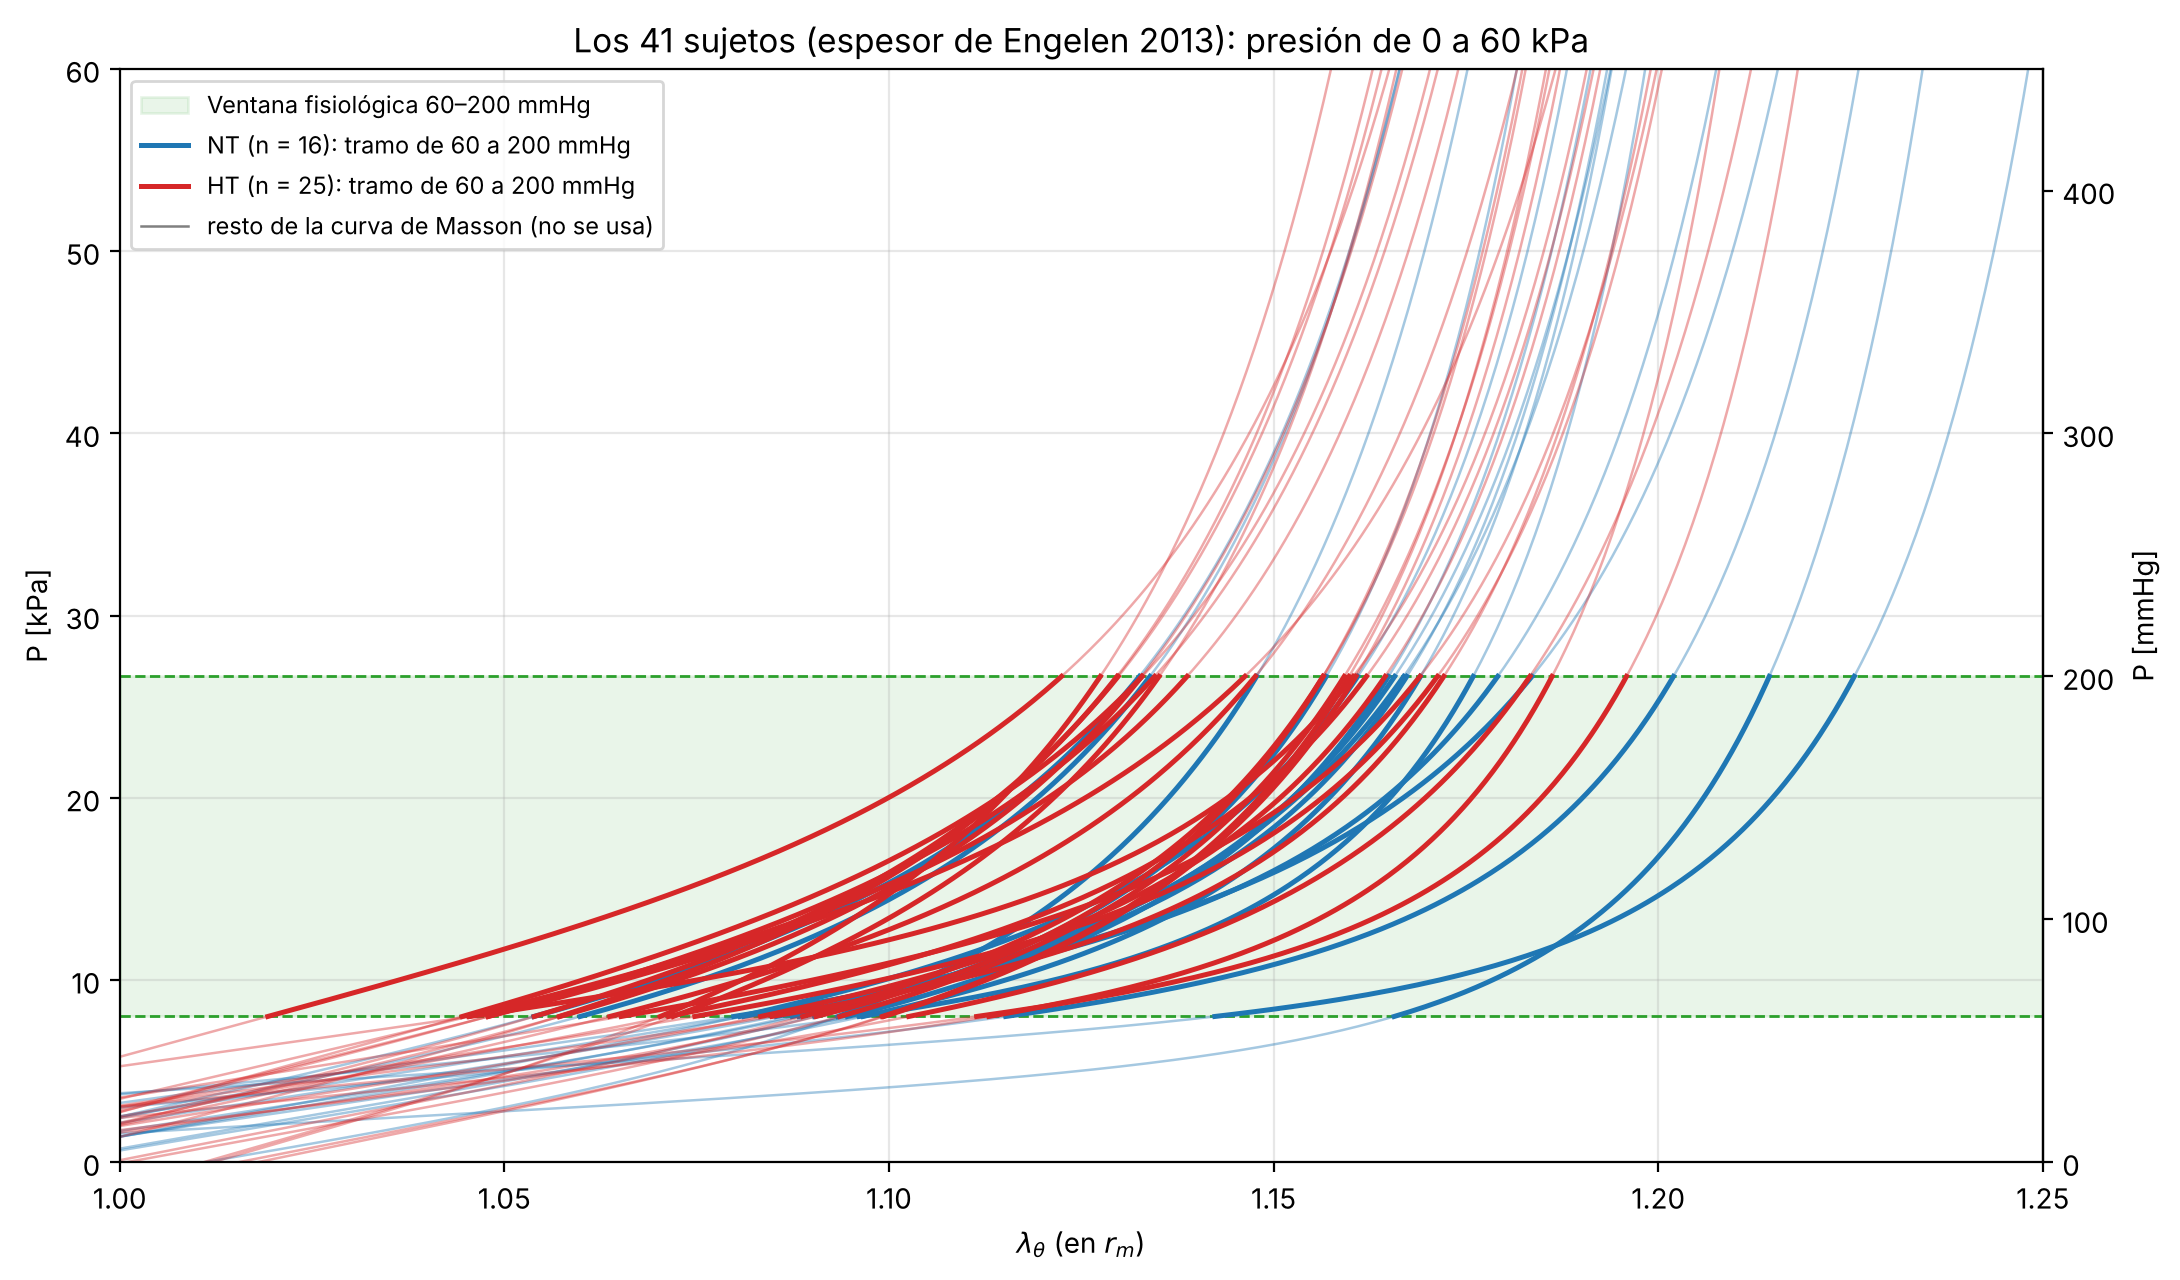

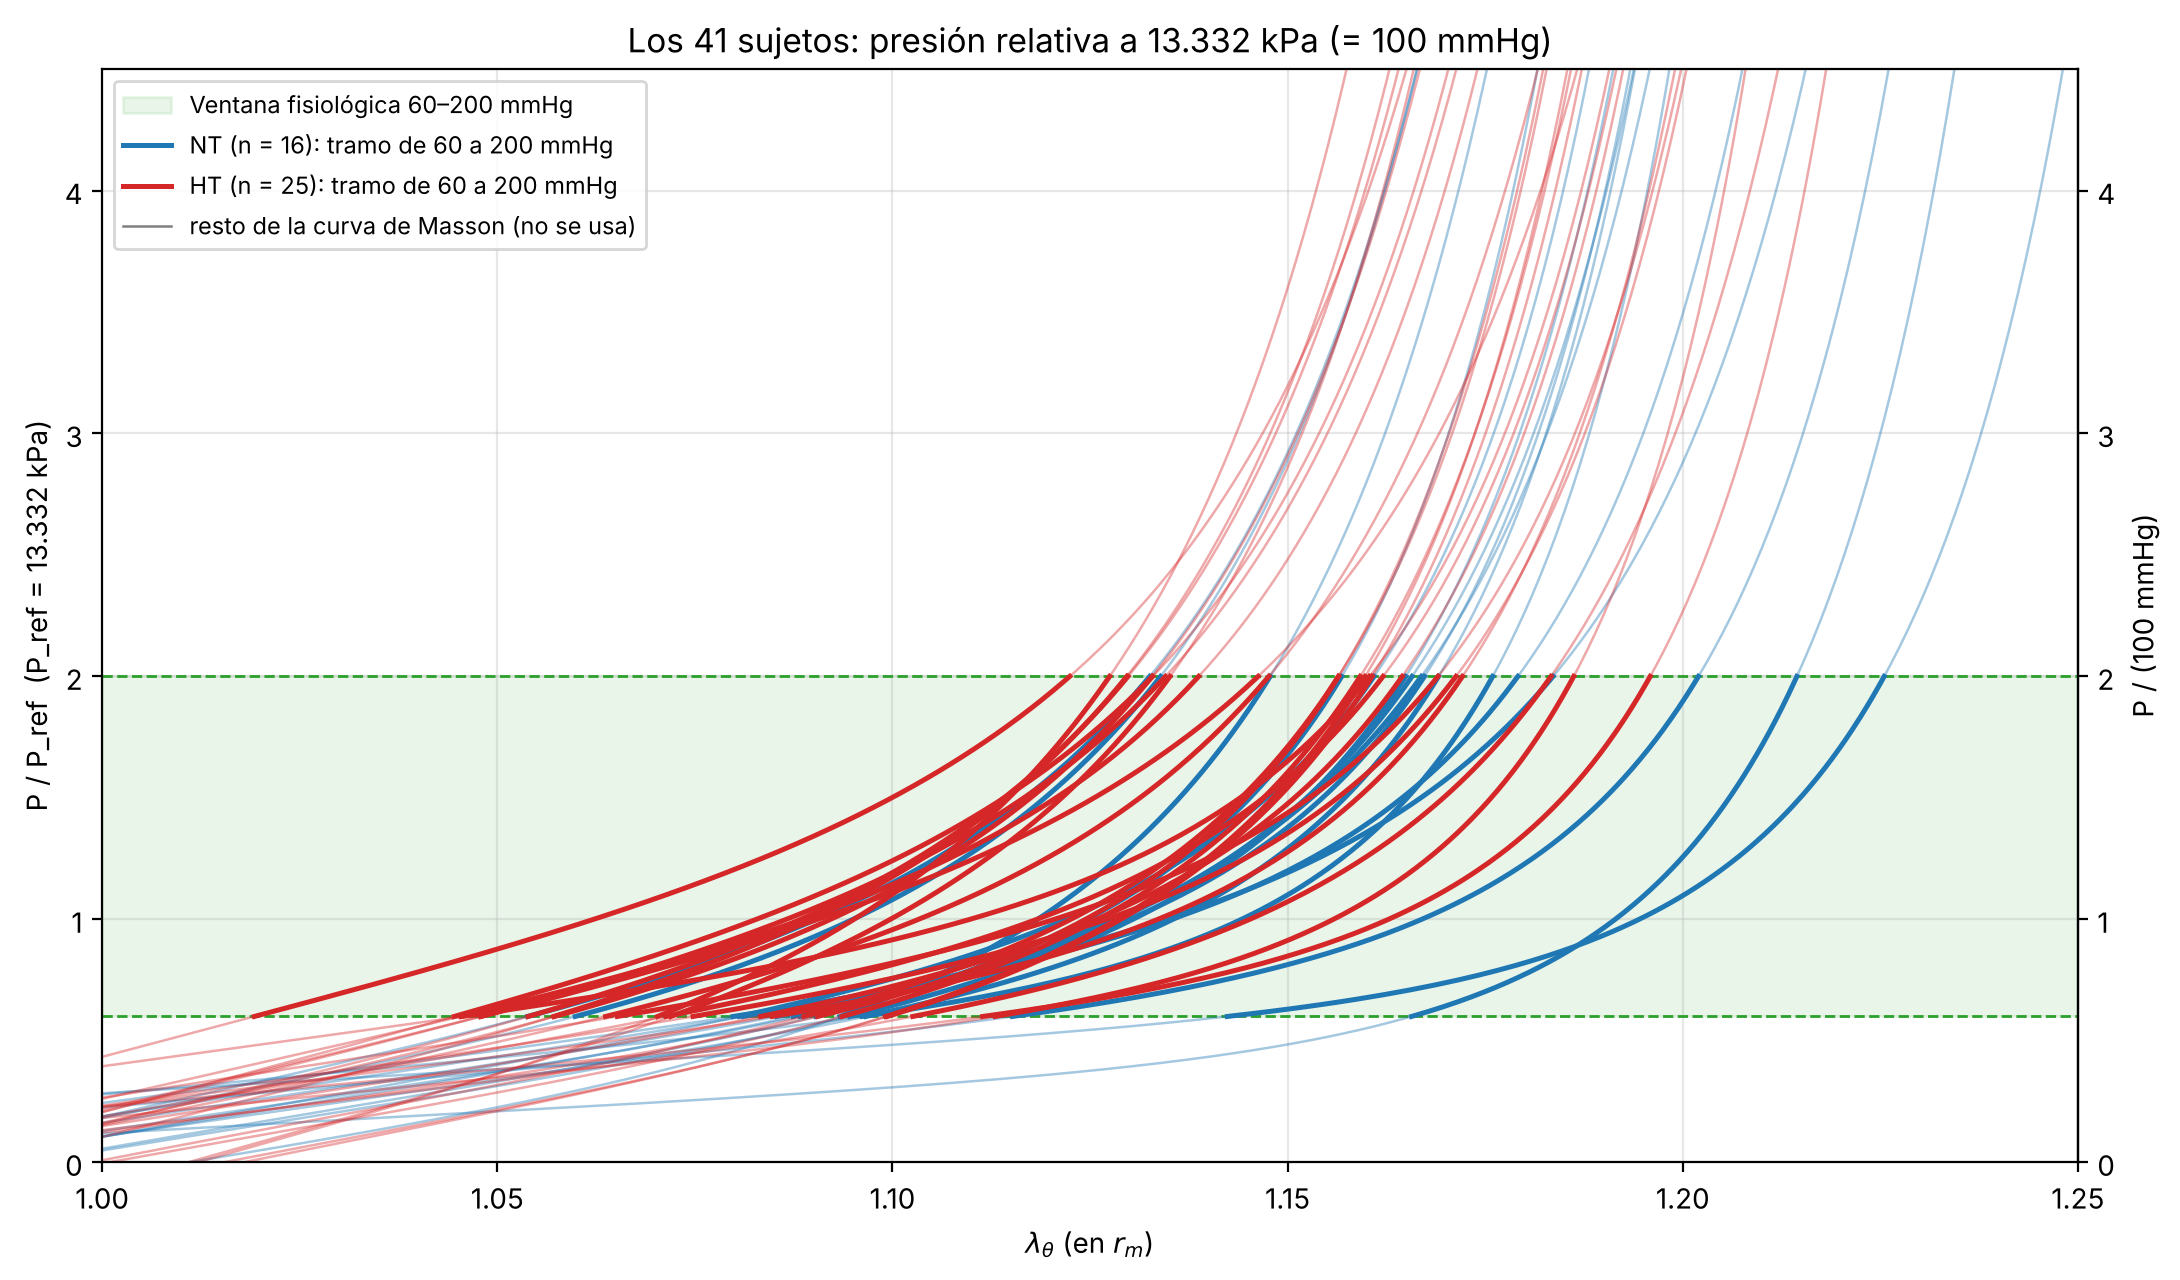

In [2]:
# CELDA 1: LOS 41 SUJETOS — ley de Masson, geometría documentada y curva diámetro–presión λθ(P)
#   P(λ) = ∫ σθθ/r dr sobre la pared (Masson: incompresible, ángulo de apertura Θ0, λz fijo). El espesor h de cada sujeto es el
#   IMT de referencia para su edad y sexo (Engelen 2013). Luego se invierte: λθ(P) en la ventana de P_MIN a P_MAX mmHg.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

COLS_PARAM = ["Rm_mm", "Theta0_deg", "lambda_ax", "c_kPa", "c1_kPa", "c2", "c1circ_kPa", "c2circ", "alpha_deg",
              "Tm_kPa", "lambda0", "lambda_m", "a_kPa", "b"]


def imt_mm(edad, sexo):
    """Mediana del IMT de carótida común [mm] para la edad y el sexo (Engelen et al. 2013, Tabla 3; lineal entre 15 y 85 años)."""
    e0, v0, d5 = IMT_ENGELEN[sexo]
    return (v0 + d5 * (np.clip(edad, 15, 85) - e0) / 5.0) / 1000.0


def sigma_masson(lt, p):
    """σθθ(λθ) [kPa]: elastina neo-Hookeana + 4 familias de colágeno + tono activo (Masson et al. 2011)."""
    lt = np.asarray(lt, float)
    lz, al = p["lambda_ax"], np.deg2rad(p["alpha_deg"])
    lam_d = np.sqrt(lt ** 2 * np.sin(al) ** 2 + lz ** 2 * np.cos(al) ** 2)
    suma = np.zeros_like(lt)
    for lam_k, c1, c2, ang in [(lz * np.ones_like(lt), p["c1_kPa"], p["c2"], 0.0), (lt, p["c1circ_kPa"], p["c2circ"], np.pi / 2),
                               (lam_d, p["c1_kPa"], p["c2"], al), (lam_d, p["c1_kPa"], p["c2"], -al)]:
        E = lam_k ** 2 - 1.0
        suma = suma + c1 * E * np.exp(c2 * E ** 2) * np.sin(ang) ** 2
    activo = p["Tm_kPa"] * lt * (1.0 - ((p["lambda_m"] - lt) / (p["lambda_m"] - p["lambda0"])) ** 2)
    return -p["c_kPa"] * (1.0 / (lt * lz)) ** 2 + p["c_kPa"] * lt ** 2 + lt ** 2 * suma + activo


def presion_arteria(lt_m, p):
    """P(λθ en r_m) [kPa], pared gruesa con la cinemática de Masson y espesor p['h_mm']."""
    lt_m = np.asarray(lt_m, float)
    Th, lz, Rm, H = np.deg2rad(p["Theta0_deg"]), p["lambda_ax"], p["Rm_mm"], p["h_mm"]
    rm = lt_m * Th * Rm / np.pi
    rr = (rm - H)[:, None] + H * np.linspace(0.0, 1.0, N_RADIAL)[None, :]
    R = np.sqrt(np.maximum(Rm ** 2 - (np.pi * lz / Th) * (rm[:, None] ** 2 - rr ** 2), 1e-12))
    return np.trapezoid(sigma_masson(np.pi * rr / (Th * R), p) / rr, rr, axis=1)


def invertir(P_de_l, x=X_FINO):
    """λ(P) en P_GRID a partir de P(λ) en x; None si P(λ) no es creciente o no cubre la ventana."""
    P = np.maximum.accumulate(np.asarray(P_de_l, float))
    if not np.all(np.isfinite(P)) or P[0] > P_GRID[0] or P[-1] < P_GRID[-1]:
        return None
    k = np.flatnonzero(np.diff(P) > 1e-9)
    return np.interp(P_GRID, P[k + 1], x[k + 1])


POB = pd.concat([pd.read_csv(f"{DIR_MASSON}/{f}").assign(grupo=g) for f, g in
                 [("tabla2_masson_NT.csv", "NT"), ("tabla4_masson_HT.csv", "HT")]], ignore_index=True)
POB["id"] = POB["grupo"] + POB["subject"].map("{:02d}".format)
POB["h_mm"] = [imt_mm(e, s) for e, s in zip(POB["age"], POB["gender"])]
POB_P = np.array([presion_arteria(X_FINO, r) for _, r in POB.iterrows()])          # P(λ) en X_FINO [kPa]
_inv = [invertir(p) for p in POB_P]
assert all(v is not None for v in _inv), "algún sujeto no cubre la ventana de presión dentro de X_FINO"
POB_L = np.array(_inv)                                                             # λθ(P) en P_GRID: la curva objetivo
_rng = np.random.default_rng(SEED)
POB["test"] = False
for g in ("NT", "HT"):
    i_g = POB.index[POB["grupo"] == g].to_numpy()
    POB.loc[_rng.choice(i_g, size=int(round(FRAC_SUJETOS_TEST * len(i_g))), replace=False), "test"] = True
MASK_TEST = POB["test"].to_numpy()
MASK_TRAIN = ~MASK_TEST
POB["lambda_60"], POB["lambda_200"] = POB_L[:, 0], POB_L[:, -1]
print(f"✅ 41 sujetos | espesor (IMT, Engelen 2013): {POB.h_mm.min():.3f}–{POB.h_mm.max():.3f} mm (mediana {POB.h_mm.median():.3f}) | "
      f"λθ en 60 mmHg: {POB_L[:, 0].min():.3f}–{POB_L[:, 0].max():.3f} | en 200 mmHg: {POB_L[:, -1].min():.3f}–{POB_L[:, -1].max():.3f}")
print(f"   test: {', '.join(POB.id[MASK_TEST])}")
print(POB[["id", "age", "gender", "Rm_mm", "h_mm", "lambda_60", "lambda_200"]].round(3).to_string(index=False))



def eje_mmhg(ax, escala=1.0):
    """Ordenada derecha en mmHg, equivalente a la izquierda (P [kPa] si escala = 1; P/P_ref si escala = P_REF_KPA)."""
    a2 = ax.secondary_yaxis("right", functions=(lambda v: v * escala / MMHG, lambda v: v * MMHG / escala))
    a2.set_ylabel("P [mmHg]")
    return a2


_mx = (X_FINO >= 1.00) & (X_FINO <= 1.25)


def figura_sujetos(escala, etq_izq, sec_fun, etq_der, archivo, titulo):
    """41 sujetos: curva completa de Masson (fina) y tramo que se usa, 60–200 mmHg (gruesa). Presión dividida por `escala`."""
    fig, ax = plt.subplots(figsize=(11, 6.5))
    ax.axhspan(P_GRID[0] / escala, P_GRID[-1] / escala, color="tab:green", alpha=0.10, label="Ventana fisiológica 60–200 mmHg")
    for v in (P_GRID[0], P_GRID[-1]):
        ax.axhline(v / escala, color="tab:green", lw=1, ls="--")
    for g, c in (("NT", "tab:blue"), ("HT", "tab:red")):
        m = (POB.grupo == g).to_numpy()
        for i in np.flatnonzero(m):
            ax.plot(X_FINO[_mx], POB_P[i, _mx] / escala, color=c, lw=0.9, alpha=0.4)
            ax.plot(POB_L[i], P_GRID / escala, color=c, lw=1.8)
        ax.plot([], [], color=c, lw=1.8, label=f"{g} (n = {m.sum()}): tramo de 60 a 200 mmHg")
    ax.plot([], [], color="0.5", lw=0.9, label="resto de la curva de Masson (no se usa)")
    ax.set(xlim=(1.0, 1.25), ylim=(0, 60 / escala), xlabel=ETQ_L, ylabel=etq_izq, title=titulo)
    a2 = ax.secondary_yaxis("right", functions=sec_fun)
    a2.set_ylabel(etq_der)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8.5, loc="upper left")
    fig.tight_layout()
    plt.savefig(archivo, dpi=180, bbox_inches="tight")
    plt.show()


# 1) Escala absoluta: P [kPa] a la izquierda, P [mmHg] a la derecha
figura_sujetos(1.0, "P [kPa]", (lambda v: v / MMHG, lambda v: v * MMHG), "P [mmHg]", f"sujetos_P_kPa_{VERSION}.png",
               "Los 41 sujetos (espesor de Engelen 2013): presión de 0 a 60 kPa")
# 2) Escala relativa: P / 13,332 kPa a la izquierda y P / 100 mmHg a la derecha (13,332 kPa = 100 mmHg: los dos ejes coinciden)
figura_sujetos(P_REF_KPA, f"P / P_ref  (P_ref = {P_REF_KPA:.3f} kPa)", (lambda v: v * P_REF_KPA / MMHG / 100.0, lambda v: v * 100.0 * MMHG / P_REF_KPA),
               "P / (100 mmHg)", f"sujetos_P_relativa_{VERSION}.png", f"Los 41 sujetos: presión relativa a {P_REF_KPA:.3f} kPa (= 100 mmHg)")

## Celda 2 — Arterias sintéticas

In [3]:
# CELDA 2: ESPACIO DE TRABAJO — arterias sintéticas (ley de Masson con parámetros de los sujetos de entrenamiento, mezclados y perturbados)
#   2 constitutiva: mezcla de 2–3 sujetos + perturbación chica   3 amplia: 2–4 sujetos, perturbación grande y extrapolación
#   5 uniforme: cada parámetro al azar entre el mínimo y el máximo de los sujetos   6 pacientes: los 31 de entrenamiento
#   El espesor h se mezcla igual que los parámetros (y se perturba un 10 %). Se acepta la curva si cubre la ventana 60–200 mmHg.
import numpy as np
import pandas as pd

N_FAM = {2: 4000, 3: 2500, 5: 1500, 6: 1000}
FAMILIAS = {0: "injerto: un material", 1: "injerto: combinada", 2: "constitutiva", 3: "constitutiva_amplia", 5: "constitutiva_uniforme",
            6: "pacientes"}
PERTURB = {2: dict(k=(2, 3), sd_mult=0.10, sd_adit=0.15, gamma=(1.0, 1.0)), 3: dict(k=(2, 4), sd_mult=0.20, sd_adit=0.30, gamma=(1.0, 1.35))}
PARAM_MULT = ["Rm_mm", "c_kPa", "c1_kPa", "c1circ_kPa", "Tm_kPa", "a_kPa", "h_mm"]
COLS = COLS_PARAM + ["h_mm"]
PARAM_ADIT = [c for c in COLS if c not in PARAM_MULT]
rng = np.random.default_rng(2026)
TH = POB.loc[MASK_TRAIN, COLS].to_numpy(float)
SD = POB[COLS].to_numpy(float).std(axis=0)
ix = {c: i for i, c in enumerate(COLS)}
iM, iA = [ix[c] for c in PARAM_MULT], [ix[c] for c in PARAM_ADIT]
es_mult = np.isin(np.arange(len(COLS)), iM)
a_z = lambda t: np.where(es_mult, np.log(np.maximum(t, 1e-9)), t)
de_z = lambda z: np.where(es_mult, np.exp(np.where(es_mult, z, 0.0)), z)
Z = a_z(TH)


def curva(th):
    """λθ(P) de una arteria con parámetros th, o None si no es válida."""
    if th[ix["lambda_m"]] <= th[ix["lambda0"]] + 0.2:
        return None
    try:
        return invertir(presion_arteria(X_FINO, dict(zip(COLS, th))))
    except FloatingPointError:
        return None


def sortear(f):
    if f == 5:
        return curva(de_z(rng.uniform(a_z(TH.min(0)), a_z(TH.max(0)))))
    cfg = PERTURB[f]
    k = rng.integers(cfg["k"][0], cfg["k"][1] + 1)
    idx = rng.choice(len(TH), size=k, replace=False)
    w = rng.dirichlet(np.ones(k))
    z = Z.mean(0) + rng.uniform(*cfg["gamma"]) * (w @ Z[idx] - Z.mean(0))
    z[iM] += rng.normal(0.0, cfg["sd_mult"], size=len(iM))
    z[iA] += rng.normal(0.0, cfg["sd_adit"], size=len(iA)) * SD[iA]
    th = de_z(z)
    th[ix["alpha_deg"]] = np.clip(th[ix["alpha_deg"]], 5.0, 85.0)
    th[ix["lambda_ax"]] = max(th[ix["lambda_ax"]], 1.0)
    th[[ix["c2"], ix["c2circ"]]] = np.maximum(th[[ix["c2"], ix["c2circ"]]], 0.5)
    th[ix["Theta0_deg"]] = np.clip(th[ix["Theta0_deg"]], 60.0, 300.0)
    th[ix["h_mm"]] = np.clip(th[ix["h_mm"]], 0.35, 0.90)
    return curva(th)


LIMPIAS, ACEPTACION = {}, {}
np.seterr(all="ignore")
for f in (2, 3, 5):
    Y, intentos = [], 0
    while len(Y) < N_FAM[f]:
        y, intentos = sortear(f), intentos + 1
        if y is not None:
            Y.append(y)
    LIMPIAS[f], ACEPTACION[f] = np.array(Y), N_FAM[f] / intentos
LIMPIAS[6] = POB_L[MASK_TRAIN][np.resize(np.arange(MASK_TRAIN.sum()), N_FAM[6])]
W_ESP = np.vstack([LIMPIAS[f] for f in (2, 3, 5)])
print(f"✅ Espacio de trabajo: {len(W_ESP)} arterias sintéticas | aceptación: "
      + ", ".join(f"{FAMILIAS[f]} {100 * ACEPTACION[f]:.1f}%" for f in (2, 3, 5))
      + f" | λθ en 60 mmHg: {W_ESP[:, 0].min():.3f}–{W_ESP[:, 0].max():.3f} | en 200 mmHg: {W_ESP[:, -1].min():.3f}–{W_ESP[:, -1].max():.3f}")

✅ Espacio de trabajo: 8000 arterias sintéticas | aceptación: constitutiva 100.0%, constitutiva_amplia 100.0%, constitutiva_uniforme 99.9% | λθ en 60 mmHg: 0.984–1.198 | en 200 mmHg: 1.047–1.249


## Celda 3 — El injerto de pared gruesa (rigidez recalibrada)

In [4]:
# CELDA 3: EL INJERTO — tubo de pared gruesa, una capa por material (rectas truncadas) y PREESTIRAMIENTO δ
#   Material j: σθθ − σrr = E_j·max(0, λ − κ_j), con λ el estiramiento circunferencial LOCAL de la capa.
#   Diseño del injerto: espesores h_j [mm] y un preestiramiento común δ (rizado/montaje de las fibras al fabricar): cada capa
#   engancha cuando la pared media llega a k_j + δ. Con nudos fijos, las ventanas 60–200 mmHg de los sujetos (λ de 1,02 a 1,23)
#   son tan distintas que cada sujeto «ve» solo 1 o 2 nudos; δ corre todos los nudos juntos y lo resuelve.
#   Tubo incompresible, deformación plana, capas pegadas (la de menor nudo junto a la sangre): r² − r_i² = R² − R_i², λ = r/R.
#   P = Σ_j ∫_capa j σ_j/r dr. R_REF = mediana de Θ0·R_m/π de los 41 sujetos (Masson).
#   Módulos E_j: calibrados para que, en pared delgada, el sujeto que más necesita de cada material use 0,2 mm de él (pared total ≈ 1–2 mm).
import numpy as np
import pandas as pd
from scipy.optimize import minimize_scalar

NUDOS = np.asarray(MATERIALES[N_BASES]["nudos"], float)
ORDEN = np.argsort(NUDOS)
R_REF = float(np.median(np.deg2rad(POB["Theta0_deg"]) * POB["Rm_mm"] / np.pi))
_GX, _GW = np.polynomial.legendre.leggauss(N_GAUSS_CAPA)
DELTA_MAX, H_CALIBRA = 0.25, 0.2


def delgada(l, d):
    """Pared delgada: P ≈ Σ c_j·max(0, λ − k_j − δ), c_j = E_j·h_j/R. Devuelve (c, e_máx en λ [% del rango])."""
    B = np.maximum(0.0, l[:, None] - (NUDOS + d)[None, :])
    c = np.linalg.lstsq(B, P_GRID, rcond=None)[0]
    Pf = B @ c
    return c, float(np.abs((P_GRID - Pf) / np.maximum(np.gradient(Pf, l), 1e-9)).max() / np.ptp(l) * 100)


def delgada_mejor(l):
    ds = np.linspace(-DELTA_MAX, DELTA_MAX, 101)
    d0 = ds[int(np.argmin([delgada(l, d)[1] for d in ds]))]
    d = minimize_scalar(lambda d: delgada(l, d)[1], bounds=(d0 - 0.005, d0 + 0.005), method="bounded").x
    return d, delgada(l, d)[0]


_C_SUJ = np.array([delgada_mejor(l)[1] for l in POB_L[MASK_TRAIN]])
E_MAT = np.maximum(_C_SUJ.max(0), 1.0) * R_REF / H_CALIBRA * np.asarray(E_ESCALA)   # V59: recalibrada (tope de 20 láminas)            # [kPa por unidad de λ]


def _geometria(h):
    hs = np.maximum(np.asarray(h, float), 1e-6)[ORDEN]
    Ri = R_REF - hs.sum() / 2
    return Ri, Ri + np.concatenate([[0.0], np.cumsum(hs)])


def aportes(h, d, x):
    """Presión [kPa] que aporta cada capa por mm de espesor, para λ de pared media x (una columna por material)."""
    hh = np.maximum(np.asarray(h, float), 1e-6)
    Ri, Rb = _geometria(hh)
    ri2 = (np.asarray(x) * R_REF) ** 2 - (R_REF ** 2 - Ri ** 2)
    B = np.zeros((len(x), N_BASES))
    for pos, j in enumerate(ORDEN):
        a, b = Rb[pos], Rb[pos + 1]
        Rc = (a + b) / 2
        kap = np.sqrt(max(((NUDOS[j] + d) * R_REF) ** 2 - (R_REF ** 2 - Ri ** 2) + Rc ** 2 - Ri ** 2, 1e-12)) / Rc
        R = Rc + (b - a) / 2 * _GX
        w = (b - a) / 2 * _GW
        r = np.sqrt(np.maximum(ri2[:, None] + R[None, :] ** 2 - Ri ** 2, 1e-12))
        B[:, j] = (E_MAT[j] * np.maximum(0.0, r / R[None, :] - kap) * R[None, :] / r ** 2 * w[None, :]).sum(1) / hh[j]
    return B


X_INJ = np.linspace(0.80, 1.45, 651)


def curva_injerto(th):
    """λ_m(P) del injerto con diseño th = (h_1 … h_N, δ), en P_GRID."""
    th = np.asarray(th, float)
    P = np.maximum.accumulate(aportes(th[:-1], th[-1], X_INJ) @ np.maximum(th[:-1], 0.0))
    k = np.flatnonzero(np.diff(P) > 1e-9)
    if len(k) < 2:
        return np.full(N_P, X_INJ[0])
    return np.interp(P_GRID, P[k + 1], X_INJ[k + 1], left=X_INJ[0], right=X_INJ[-1])


def errores_l(yl, l):
    """(E_rms, e_máx) en % del rango de λ de la curva objetivo yl (de 60 a 200 mmHg)."""
    r, d = np.asarray(yl) - np.asarray(l), np.ptp(yl)
    return 100 * np.sqrt(np.mean(r ** 2)) / d, 100 * np.abs(r).max() / d


print(f"Materiales (capa 1 = junto a la sangre) | R_ref = {R_REF:.3f} mm | δ en ±{DELTA_MAX:g}:")
print(pd.DataFrame({"material": np.arange(1, N_BASES + 1), "nudo k": NUDOS, "E [kPa]": E_MAT.round(1)}).to_string(index=False))

Materiales (capa 1 = junto a la sangre) | R_ref = 3.421 mm | δ en ±0.25:
 material  nudo k  E [kPa]
        1  0.8228    522.2
        2  1.0243   1759.1
        3  1.0881   1904.0
        4  1.1226   3923.2
        5  1.1447   8874.3


## Celda 4 — Mínimos cuadrados no lineales (con el tope de láminas)

In [5]:
# CELDA 4: AJUSTE EXACTO (referencia) — mínimos cuadrados NO lineales del diseño th = (h_1 … h_N, δ)
#   min Σ_k (λ_injerto(P_k; th) − λ_objetivo(P_k))² en la ventana de presión (región de confianza, scipy least_squares).
#   Arranque: pared delgada (δ por búsqueda en grilla y h_j = c_j·R/E_j) o el que se le dé (p. ej. la red).
#   Límites solo físicos: 0 ≤ h_j ≤ H_CAPA_MAX, |δ| ≤ DELTA_MAX.
import time
import numpy as np
from scipy.optimize import least_squares

LO = np.r_[np.zeros(N_BASES), -DELTA_MAX]
HI = np.r_[np.full(N_BASES, min(H_CAPA_MAX, TOPE_LAMINAS * ESP_LAMINA_MM)), DELTA_MAX]   # V59: tope de láminas


def arranque_delgada(yl):
    d, c = delgada_mejor(yl)
    return np.r_[np.clip(c * R_REF / E_MAT, 0.0, H_CAPA_MAX), d]


def ajuste_exacto(yl, th0=None, info=False):
    th0 = arranque_delgada(yl) if th0 is None else np.asarray(th0, float)
    th0 = np.clip(th0, LO + 1e-4, HI - 1e-4)
    r = least_squares(lambda th: (curva_injerto(th) - yl) / np.ptp(yl), th0, bounds=(LO, HI), method="trf",
                      x_scale=np.r_[np.maximum(th0[:-1], 0.02), 0.01], xtol=1e-10, ftol=1e-10, max_nfev=300)
    return (r.x, r.nfev) if info else r.x


t0 = time.perf_counter()
_R = [ajuste_exacto(y, info=True) for y in POB_L]
T_EXACTO = (time.perf_counter() - t0) / len(POB_L)
TH_SUJ = np.array([r[0] for r in _R])
E_SUJ = np.array([errores_l(y, curva_injerto(th)) for y, th in zip(POB_L, TH_SUJ)])
print(f"✅ Ajuste exacto de los 41 sujetos ({1e3 * T_EXACTO:.0f} ms y {np.mean([r[1] for r in _R]):.0f} evaluaciones por sujeto): "
      f"error máx. en λ mediana {np.median(E_SUJ[:, 1]):.2f} %, peor {E_SUJ[:, 1].max():.2f} % ({POB.id[E_SUJ[:, 1].argmax()]}) | "
      f"≤ {ERROR_MAX_PCT:g} %: {(E_SUJ[:, 1] <= ERROR_MAX_PCT).sum()}/41 | pared: {TH_SUJ[:, :-1].sum(1).min():.2f}–"
      f"{TH_SUJ[:, :-1].sum(1).max():.2f} mm | δ: {TH_SUJ[:, -1].min():.3f}…{TH_SUJ[:, -1].max():.3f}")

✅ Ajuste exacto de los 41 sujetos (97 ms y 35 evaluaciones por sujeto): error máx. en λ mediana 1.24 %, peor 2.12 % (HT23) | ≤ 3 %: 41/41 | pared: 0.58–1.30 mm | δ: -0.039…0.079


## Celda 5 — Referencia: el minimax del tubo

In [6]:
# CELDA 5: LA REFERENCIA — el procedimiento de 3 pasos de V47 (el «minimax» del nivel tubo), con el tope de 20 láminas
#   Paso 1: arranque de pared delgada · Paso 2: mínimos cuadrados no lineales de pared gruesa (reales) ·
#   Paso 3: láminas enteras con minimax no lineal contra la curva del paso 2 (piso/techo, δ reajustado y mejora local).
import time
import itertools
import numpy as np
import pandas as pd
from scipy.optimize import least_squares, minimize_scalar

P_NORMAS = (8, 16, 32, 64)


def residuo_pct(th, yl):
    return 100.0 * (curva_injerto(th) - yl) / np.ptp(yl)


def minimax_continuo(yl, th0):
    th = np.clip(np.asarray(th0, float), LO + 1e-5, HI - 1e-5)
    for p in P_NORMAS:
        s = max(float(np.abs(residuo_pct(th, yl)).max()), 1e-3)
        r = least_squares(lambda t: (np.abs(residuo_pct(t, yl)) / s + 1e-12) ** (p / 2), th, bounds=(LO, HI), method="trf",
                          x_scale=np.r_[np.maximum(th[:-1], 0.02), 0.01], xtol=1e-10, ftol=1e-10, max_nfev=200)
        if np.abs(residuo_pct(r.x, yl)).max() <= np.abs(residuo_pct(th, yl)).max():
            th = r.x
    return th


def e_max_th(yl, th):
    e = float(np.abs(residuo_pct(th, yl)).max())
    return e if np.isfinite(e) else np.inf


def a_enteros(yl, th, esp=None, n_mejores=8):
    """Diseño con láminas enteras (n_j ≥ 0) de espesor esp y δ reajustado, por el criterio del peor punto. Devuelve (θ, n)."""
    esp = ESP_LAMINA_MM if esp is None else esp
    n0 = np.maximum(th[:-1], 0.0) / esp
    opciones = [sorted({min(int(np.floor(v)), TOPE_LAMINAS), min(int(np.ceil(v)), TOPE_LAMINAS)}) for v in n0]
    cand = sorted(((e_max_th(yl, np.r_[np.asarray(n, float) * esp, th[-1]]), np.asarray(n, float)) for n in itertools.product(*opciones)),
                  key=lambda c: c[0])
    mejor = (cand[0][0], th[-1], cand[0][1])

    def _delta_opt(n, d0):
        r = minimize_scalar(lambda d: e_max_th(yl, np.r_[n * esp, d]), bounds=(max(d0 - 0.03, -DELTA_MAX), min(d0 + 0.03, DELTA_MAX)),
                            method="bounded", options=dict(xatol=1e-5))
        return r.x, r.fun

    for e0, n in cand[:n_mejores]:
        d, e = _delta_opt(n, th[-1])
        if e < mejor[0]:
            mejor = (e, d, n)
    e, d, n = mejor
    for _ in range(20):                                  # mejora local: mover una lámina mientras baje el peor error
        vecinos = [n + s * np.eye(N_BASES)[j] for j in range(N_BASES) for s in (-1, 1)]
        vecinos += [n + np.eye(N_BASES)[i] - np.eye(N_BASES)[j] for i in range(N_BASES) for j in range(N_BASES) if i != j]
        vecinos = [v for v in vecinos if v.min() >= 0 and v.max() <= TOPE_LAMINAS]
        pre = sorted(((e_max_th(yl, np.r_[v * esp, d]), i) for i, v in enumerate(vecinos)))[:n_mejores]
        dd, ee, nn = min(((*_delta_opt(vecinos[i], d), vecinos[i]) for _, i in pre), key=lambda c: c[1])
        if ee < e - 1e-6:
            e, d, n = ee, dd, nn
        else:
            break
    return np.r_[n * esp, d], n.astype(int)




def errores_l(y, l):
    """(Erms %, e_max %) de la curva l contra y, en % del rango de y."""
    r = 100.0 * (np.asarray(l) - y) / np.ptp(y)
    return float(np.sqrt(np.mean(r ** 2))), float(np.abs(r).max())


def minimax_tubo(y):
    """Diseño entero de referencia: (θ = (h_1…h_N, δ), n láminas)."""
    th_mc = ajuste_exacto(y)
    return a_enteros(curva_injerto(th_mc), th_mc)


t0 = time.perf_counter()
REF_SUJ = [minimax_tubo(y) for y in POB_L]
T_MINIMAX = (time.perf_counter() - t0) / len(POB_L)
E_REF = np.array([e_max_th(y, th) for y, (th, n) in zip(POB_L, REF_SUJ)])
N_REF = np.array([n for th, n in REF_SUJ])
print(f"✅ Referencia (minimax del tubo) en los 41 sujetos: {(E_REF <= ERROR_MAX_PCT).sum()}/41 cumplen | mediana {np.median(E_REF):.2f} % | "
      f"peor {E_REF.max():.2f} % | láminas por material: máx. {N_REF.max()} | {T_MINIMAX:.2f} s por sujeto")


✅ Referencia (minimax del tubo) en los 41 sujetos: 41/41 cumplen | mediana 1.66 % | peor 2.88 % | láminas por material: máx. 20 | 0.25 s por sujeto


## Celda 6 — Dataset con etiquetas enteras

In [7]:
# CELDA 6: DATASET CON ETIQUETAS ENTERAS (láminas n_1…n_N de 0 a 20 y preestiramiento δ)
#   Familia 1 (injertos): se sortean las láminas y δ, se calcula su curva → la etiqueta es exactamente ese diseño.
#   Familias 2, 3, 5 y 6 (arterias): la etiqueta es el diseño entero de referencia (Celda 5). Es lento (≈ 0,4 s por curva):
#   se calcula en paralelo, se guarda en ARCHIVO_ETIQUETAS y las veces siguientes se carga.
import os
import time
import multiprocessing as mp
import numpy as np

N_INJERTOS = 6000
rng_b = np.random.default_rng(2028)
N_GEN_MAX = np.minimum(np.ceil(1.3 * N_REF[MASK_TRAIN].max(0)), TOPE_LAMINAS).astype(int)
D_GEN = (min(th[-1] for th, n in REF_SUJ) - 0.03, max(th[-1] for th, n in REF_SUJ) + 0.03)


def _sortear_injerto():
    n = np.zeros(N_BASES, int)
    act = rng_b.choice(N_BASES, size=rng_b.integers(2, N_BASES + 1), replace=False)
    n[act] = rng_b.integers(0, N_GEN_MAX[act] + 1)
    return n, rng_b.uniform(*D_GEN)


def _etiqueta(y):
    th, n = minimax_tubo(y)
    return np.r_[n, th[-1]]


if os.path.exists(ARCHIVO_ETIQUETAS):
    _d = np.load(ARCHIVO_ETIQUETAS)
    N_INJ, D_INJ, Y_INJ, ET_ART = _d["N_INJ"], _d["D_INJ"], _d["Y_INJ"], _d["ET_ART"]
    print(f"📦 Etiquetas cargadas de '{ARCHIVO_ETIQUETAS}'")
else:
    t0 = time.time()
    N_INJ, D_INJ, Y_INJ = [], [], []
    while len(N_INJ) < N_INJERTOS:                                     # injertos que cubren la ventana con forma razonable
        n, d = _sortear_injerto()
        l = curva_injerto(np.r_[n * ESP_LAMINA_MM, d])
        if X_INJ[0] + 0.01 < l[0] and l[-1] < X_INJ[-1] - 0.01 and np.ptp(l) > 0.02:
            N_INJ.append(n); D_INJ.append(d); Y_INJ.append(l)
    N_INJ, D_INJ, Y_INJ = np.array(N_INJ), np.array(D_INJ), np.array(Y_INJ)
    _Y = np.vstack([LIMPIAS[f] for f in (2, 3, 5)])
    print(f"⏳ Diseño entero de referencia de {len(_Y)} arterias sintéticas en paralelo...", flush=True)
    with mp.get_context("fork").Pool(max(1, os.cpu_count())) as pool:
        ET_ART = np.array(pool.map(_etiqueta, list(_Y), chunksize=50))
    ET_ART = np.vstack([ET_ART, np.array([np.r_[n, th[-1]] for th, n in np.array(REF_SUJ, dtype=object)[MASK_TRAIN]])])
    np.savez_compressed(ARCHIVO_ETIQUETAS, N_INJ=N_INJ, D_INJ=D_INJ, Y_INJ=Y_INJ, ET_ART=ET_ART)
    print(f"✅ Etiquetas en {(time.time() - t0) / 60:.1f} min → {ARCHIVO_ETIQUETAS}")

_n6 = MASK_TRAIN.sum()
_rep = np.resize(np.arange(_n6), N_FAM[6])
Y_ALL = np.vstack([Y_INJ] + [LIMPIAS[f] for f in (2, 3, 5)] + [POB_L[MASK_TRAIN][_rep]])
ET_ALL = np.vstack([np.c_[N_INJ, D_INJ], ET_ART[:-_n6], ET_ART[-_n6:][_rep]])
Z = ET_ALL[:, :N_BASES].astype(int)                                     # láminas enteras (etiqueta)
DELTA = ET_ALL[:, -1]                                                     # preestiramiento (etiqueta)
familia = np.concatenate([np.full(len(Y_INJ), 1)] + [np.full(N_FAM[f], f) for f in (2, 3, 5, 6)]).astype(np.int8)
assert Z.max() <= TOPE_LAMINAS and Z.min() >= 0
print(f"✅ Dataset: {len(Y_ALL)} curvas ({len(Y_INJ)} injertos + {len(Y_ALL) - len(Y_INJ)} arterias) | láminas por material ≤ {Z.max()} | "
      f"δ de {DELTA.min():.3f} a {DELTA.max():.3f}")


📦 Etiquetas cargadas de 'etiquetas_enteras_tubo_v59_5.npz'
✅ Dataset: 15000 curvas (6000 injertos + 9000 arterias) | láminas por material ≤ 20 | δ de -0.097 a 0.140


## Celda 7 — Partición y normalización

In [8]:
# CELDA 7: PARTICIÓN TRAIN / VAL / TEST Y NORMALIZACIÓN
#   Entrada: la curva λθ(P) en los 141 valores de presión, estandarizada. Salidas: láminas enteras (ordinal) y δ estandarizado.
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

idx_trval, idx_test = train_test_split(np.arange(len(Y_ALL)), test_size=0.15, random_state=SEED, stratify=familia)
idx_train, idx_val = train_test_split(idx_trval, test_size=0.12, random_state=SEED, stratify=familia[idx_trval])
sx = StandardScaler().fit(Y_ALL[idx_train])
D_MED, D_SD = float(DELTA[idx_train].mean()), float(DELTA[idx_train].std())
X_train, X_val, X_test = (sx.transform(Y_ALL[i]).astype(np.float32) for i in (idx_train, idx_val, idx_test))
K = TOPE_LAMINAS + 1
print(f"✅ Train {len(idx_train)} | Val {len(idx_val)} | Test {len(idx_test)} | {K} cantidades posibles por material (0 a {TOPE_LAMINAS})")


✅ Train 11220 | Val 1530 | Test 2250 | 21 cantidades posibles por material (0 a 20)


## Celda 8 — La red en cadena ordinal para el tubo

In [9]:
# CELDA 8: LA RED EN CADENA ORDINAL PARA EL TUBO (la misma de la Figura 3 del artículo)
#   Tronco común 141 → 256 → 128 → 64 (ReLU + LayerNormalization) → h. Cabeza j: (h, m_1…m_{j−1}) → 128 → 64 → un puntaje s_j;
#   20 preguntas «¿más de k láminas?» con P(n_j > k) = σ(s_j + b_jk) (CORAL). m = vector de láminas decididas (n/20).
#   Una cabeza más para δ: (h, m_1…m_N) → 64 → δ (estandarizado). Pérdida: entropía cruzada binaria de las preguntas
#   (sumada sobre preguntas y materiales) + error cuadrático de δ. Teacher forcing: al entrenar, m son las láminas de la etiqueta.
#   En cada época se suma a la entrada un ruido nuevo (0 a 1 % del rango de λ de cada curva).
import os, time, pickle
import numpy as np
import pandas as pd
import tensorflow as tf

tf.random.set_seed(SEED)
EPOCHS, BATCH_SIZE, RUIDO_MAX, PESO_DELTA = 800, 256, 0.01, 5.0
ESCZ = float(TOPE_LAMINAS)
_sxm, _sxs = tf.constant(sx.mean_, tf.float32), tf.constant(sx.scale_, tf.float32)


class Umbrales(tf.keras.layers.Layer):
    """CORAL: logit_k = s + b_k (k = 0…K−2), el MISMO puntaje s y un umbral b_k por pregunta «¿más de k láminas?»."""
    def __init__(self, n, **kw):
        super().__init__(**kw); self.n = n
    def build(self, shape):
        self.b = self.add_weight(name="umbrales", shape=(self.n,), initializer=tf.keras.initializers.Constant(np.linspace(2.0, -2.0, self.n)))
    def call(self, s):
        return s + self.b


def red_cadena_tubo():
    x = tf.keras.Input(shape=(N_P,), name="curva")
    m = tf.keras.Input(shape=(N_BASES,), name="laminas_decididas")
    h = x
    for u in (256, 128, 64):
        h = tf.keras.layers.Dense(u, activation="relu", kernel_regularizer=tf.keras.regularizers.l2(1e-5))(h)
        h = tf.keras.layers.LayerNormalization()(h)
    sal = []
    for j in range(N_BASES):
        e = h if j == 0 else tf.keras.layers.Concatenate()([h, tf.keras.layers.Lambda(lambda t, j=j: t[:, :j])(m)])
        e = tf.keras.layers.Dense(128, activation="relu")(e)
        e = tf.keras.layers.Dense(64, activation="relu")(e)
        sal.append(Umbrales(K - 1, name=f"m{j + 1}")(tf.keras.layers.Dense(1, use_bias=False)(e)))
    e = tf.keras.layers.Concatenate()([h, m])
    e = tf.keras.layers.Dense(64, activation="relu")(e)
    sal.append(tf.keras.layers.Dense(1, name="delta")(e))
    return tf.keras.Model([x, m], sal)


def perdida_ordinal(y, logits):
    return tf.reduce_sum(tf.nn.sigmoid_cross_entropy_with_logits(labels=y, logits=logits), axis=1)


def niveles(z):
    return (np.asarray(z)[:, None] > np.arange(K - 1)[None, :]).astype("float32")


def _objetivos(idx):
    return tuple(niveles(Z[idx, j]) for j in range(N_BASES)) + (((DELTA[idx] - D_MED) / D_SD).astype("float32")[:, None],)


def _con_ruido(entr, y):
    x, m = entr
    l = x * _sxs + _sxm
    rango = tf.reduce_max(l, axis=1, keepdims=True) - tf.reduce_min(l, axis=1, keepdims=True)
    u = tf.random.uniform([tf.shape(x)[0], 1], 0.0, RUIDO_MAX)
    return (((l + tf.random.normal(tf.shape(l)) * u * rango) - _sxm) / _sxs, m), y


RED = red_cadena_tubo()
RED.compile(optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0), loss=[perdida_ordinal] * N_BASES + ["mse"],
            loss_weights=[1.0] * N_BASES + [PESO_DELTA])
if ENTRENAR:
    t0 = time.time()
    M_va = (Z[idx_val] / ESCZ).astype("float32")
    ds = (tf.data.Dataset.from_tensor_slices(((X_train, (Z[idx_train] / ESCZ).astype("float32")), _objetivos(idx_train)))
          .shuffle(len(X_train), seed=SEED, reshuffle_each_iteration=True).batch(BATCH_SIZE)
          .map(_con_ruido, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE))
    H = RED.fit(ds, validation_data=((X_val, M_va), _objetivos(idx_val)), epochs=EPOCHS, verbose=0,
                callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=60, restore_best_weights=True),
                           tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=20, min_lr=1e-6)])
    hist = pd.DataFrame(H.history); hist.index = pd.RangeIndex(1, len(hist) + 1, name="epoca")
    hist.to_csv(ARCHIVO_HISTORIAL)
    RED.save_weights(ARCHIVO_MODELO)
    with open(ARCHIVO_SCALERS, "wb") as f:
        pickle.dump(dict(scaler_x=sx, D_MED=D_MED, D_SD=D_SD, E_MAT=E_MAT, NUDOS=NUDOS, R_REF=R_REF), f)
    print(f"✅ Red entrenada en {(time.time() - t0) / 60:.1f} min ({len(hist)} épocas; pérdida val. {hist.val_loss.min():.3f})")
else:
    RED.load_weights(ARCHIVO_MODELO)
    hist = pd.read_csv(ARCHIVO_HISTORIAL, index_col="epoca")
    with open(ARCHIVO_SCALERS, "rb") as f:
        _m = pickle.load(f)
    assert np.allclose(_m["E_MAT"], E_MAT), "la red se entrenó con otros materiales"
    sx, D_MED, D_SD = _m["scaler_x"], _m["D_MED"], _m["D_SD"]
    print(f"📦 Red cargada de '{ARCHIVO_MODELO}' ({len(hist)} épocas)")
print(f"   {RED.count_params():,} parámetros")


I0000 00:00:1794422840.507957   15238 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794422840.547324   15238 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794422841.441025   15238 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


📦 Red cargada de 'modelo_rn_cadena_tubo_v59_5.weights.h5' (409 épocas)
   167,525 parámetros


/usr/local/lib/python3.13/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 94 variables. 
  saveable.load_own_variables(store)


## Celda 9 — Cómo se usa la red

In [10]:
# CELDA 9: CÓMO SE USA LA RED — paso a paso, más dos revisiones opcionales
#   (1) Cadena: la red se evalúa N veces; en la evaluación j, m = (n_1…n_{j−1}, 0…0)/20 y se lee la cabeza j
#       (n_j = cantidad de preguntas con P > 1/2). Al final, la cabeza de δ con todas las láminas.
#   (2) δ afinado: con las láminas fijas, δ se ajusta en ±0,03 (una sola variable, Brent acotado) contra el peor punto.
#   (3) Búsqueda ±1: se prueban las 3^N combinaciones a ±1 lámina por material (sin salir de 0…20), con ese δ; en las 8 de
#       menor peor punto se vuelve a afinar δ y se elige la mejor.
#   Antes de todo, la curva se suaviza con un polinomio de grado 6 en P (no cambia una curva limpia; a una medida le quita el ruido,
#   como hace el paso 2 del minimax).
import itertools
import numpy as np
from scipy.optimize import minimize_scalar

VECINOS = np.array(list(itertools.product((-1, 0, 1), repeat=N_BASES)))


def predecir_cadena(Y):
    Y = np.atleast_2d(Y)
    Xs = sx.transform(Y).astype("float32")
    zp = np.zeros((len(Y), N_BASES), "float32")
    for j in range(N_BASES):
        zp[:, j] = (RED.predict([Xs, zp / ESCZ], batch_size=1024, verbose=0)[j] > 0).sum(1)
    d = RED.predict([Xs, zp / ESCZ], batch_size=1024, verbose=0)[-1][:, 0] * D_SD + D_MED
    return zp.astype(int), np.clip(d, -DELTA_MAX, DELTA_MAX)


def theta(n, d):
    return np.r_[np.asarray(n, float) * ESP_LAMINA_MM, d]


def afinar_delta(y, n, d0):
    r = minimize_scalar(lambda d: e_max_th(y, theta(n, d)), bounds=(max(d0 - 0.03, -DELTA_MAX), min(d0 + 0.03, DELTA_MAX)),
                        method="bounded", options=dict(xatol=1e-5))
    return (r.x, r.fun) if r.fun <= e_max_th(y, theta(n, d0)) else (d0, e_max_th(y, theta(n, d0)))


def busqueda_pm1(y, n, d):
    cand = np.clip(n[None, :] + VECINOS, 0, TOPE_LAMINAS)
    cand = np.unique(cand, axis=0)
    e = np.array([e_max_th(y, theta(c, d)) for c in cand])
    mejores = [afinar_delta(y, cand[i], d) + (cand[i],) for i in np.argsort(e)[:8]]   # δ reajustado en las 8 mejores
    d2, e2, nb = min(mejores, key=lambda t: t[1])
    return nb, d2, e2


GRADO_SUAVE = 6


def suavizar(y, g=GRADO_SUAVE):
    """Polinomio de grado g en P ajustado por mínimos cuadrados: quita el ruido de una curva medida y no cambia una limpia."""
    x = (P_GRID - P_GRID.mean()) / np.ptp(P_GRID)
    return np.polyval(np.polyfit(x, y, g), x)


def disenar_con_red(Y):
    """Para cada curva: dict con (n, δ) de la red sola, con δ afinado y con la búsqueda ±1 (todo sobre la curva suavizada)."""
    Y = np.array([suavizar(y) for y in np.atleast_2d(Y)])
    Nn, D = predecir_cadena(Y)
    out = []
    for y, n, d in zip(Y, Nn, D):
        da, _ = afinar_delta(y, n, d)
        nb, db, _ = busqueda_pm1(y, n, da)
        out.append({"red": (n, d), "red + δ": (n, da), "red ±1": (nb, db)})
    return out


## Celda 10 — Resultados con curvas limpias

In [11]:
# CELDA 10: RESULTADOS — 41 sujetos (entrenamiento y prueba) y curvas sintéticas de prueba, contra la curva original
import time
import numpy as np
import pandas as pd

METODOS = ["minimax", "red", "red + δ", "red ±1"]
RED(([sx.transform(POB_L[:2]).astype("float32"), np.zeros((2, N_BASES), "float32")]))
t0 = time.perf_counter(); DIS_RED = disenar_con_red(POB_L); T_RED = (time.perf_counter() - t0) / len(POB_L)
_fil = []
for i, (nm, y) in enumerate(zip(POB.id, POB_L)):
    th_r, n_r = REF_SUJ[i]
    dis = {"minimax": (n_r, th_r[-1]), **DIS_RED[i]}
    for m in METODOS:
        n, d = dis[m]
        er, em = errores_l(y, curva_injerto(theta(n, d)))
        _fil.append({"sujeto": nm, "conjunto": "prueba" if MASK_TEST[i] else "entrenamiento", "método": m, "Erms %": er, "e_max %": em,
                     "delta": d, "láminas": str(np.asarray(n, int).tolist()), "pared mm": np.sum(n) * ESP_LAMINA_MM,
                     **{f"n{j + 1}": int(n[j]) for j in range(N_BASES)}})
SUJ59 = pd.DataFrame(_fil)
SUJ59.to_csv(f"sujetos_{VERSION}.csv", index=False)

# curvas sintéticas de prueba (las arterias del conjunto de prueba, a lo sumo 300)
_it = idx_test[familia[idx_test] != 1][:300]
DIS_T = disenar_con_red(Y_ALL[_it])
_ft = []
for k, i in enumerate(_it):
    y = Y_ALL[i]
    dis = {"minimax": (Z[i], DELTA[i]), **DIS_T[k]}
    for m in METODOS:
        n, d = dis[m]
        _ft.append({"método": m, "e_max %": errores_l(y, curva_injerto(theta(n, d)))[1], "igual": bool(np.all(np.asarray(n) == Z[i]))})
TEST59 = pd.DataFrame(_ft)


def _res(D, grupo):
    return D.groupby("método", sort=False)["e_max %"].agg(
        mediana="median", peor="max", cumplen=lambda v: f"{(v <= ERROR_MAX_PCT).sum()}/{len(v)}").assign(grupo=grupo)


RES59 = pd.concat([_res(SUJ59[SUJ59.conjunto == "entrenamiento"], "41 sujetos: entrenamiento (31)"),
                   _res(SUJ59[SUJ59.conjunto == "prueba"], "41 sujetos: prueba (10)"),
                   _res(TEST59, f"arterias sintéticas de prueba ({len(_it)})")])
RES59.round(2).to_csv(f"resumen_{VERSION}.csv")
print(f"Diseño ENTERO (láminas de {ESP_LAMINA_MM:g} mm, a lo sumo {TOPE_LAMINAS} por material) — peor error en λ [% del rango]")
print(RES59.round(2).to_string())
print(f"\nTiempo por sujeto: minimax {T_MINIMAX:.2f} s | red (cadena + δ afinado + ±1) {T_RED:.2f} s")
print("Láminas iguales al minimax (sintéticas de prueba):", TEST59.groupby("método", sort=False)["igual"].mean().round(3).to_dict())


Diseño ENTERO (láminas de 0.025 mm, a lo sumo 20 por material) — peor error en λ [% del rango]
         mediana   peor  cumplen                                grupo
método                                                               
minimax     1.78   2.73    31/31       41 sujetos: entrenamiento (31)
red         2.12   3.46    27/31       41 sujetos: entrenamiento (31)
red + δ     1.62   2.19    31/31       41 sujetos: entrenamiento (31)
red ±1      1.49   2.07    31/31       41 sujetos: entrenamiento (31)
minimax     1.58   2.88    10/10              41 sujetos: prueba (10)
red         3.04   6.26     5/10              41 sujetos: prueba (10)
red + δ     2.05   4.51     9/10              41 sujetos: prueba (10)
red ±1      1.41   4.22     9/10              41 sujetos: prueba (10)
minimax     1.66   3.65  290/300  arterias sintéticas de prueba (300)
red         2.53  38.91  201/300  arterias sintéticas de prueba (300)
red + δ     1.55  22.18  285/300  arterias sintéticas de prueba (

## Celda 11 — Curvas medidas

In [12]:
# CELDA 11: CURVAS MEDIDAS — ruido en el diámetro o pocas presiones; el diseño se compara con la curva VERDADERA
#   El minimax recibe la curva medida (su paso 2 la suaviza y el paso 3 elige las láminas contra la curva suave).
#   La red recibe la curva medida; el δ afinado y la búsqueda ±1 se hacen contra la curva medida.
import time
import numpy as np
import pandas as pd
from scipy.interpolate import PchipInterpolator

ESC_ROB = {"ruido 0,3 %": (0.003, None), "10 presiones": (0.0, 10), "10 presiones + ruido 0,2 %": (0.002, 10)}
_rng = np.random.default_rng(SEED + 5)
_fil = []
t00 = time.time()
for esc, (r, npts) in ESC_ROB.items():
    YM = []
    for y in POB_L:
        if npts:
            pm = np.linspace(P_GRID[0], P_GRID[-1], npts)
            ym = np.interp(pm, P_GRID, y)
            ym = PchipInterpolator(pm, ym + _rng.normal(0.0, r, size=npts) * ym)(P_GRID)
        else:
            ym = y + _rng.normal(0.0, r, size=y.shape) * y
        YM.append(ym)
    YM = np.array(YM)
    DR = disenar_con_red(YM)
    for i, (nm, y, ym) in enumerate(zip(POB.id, POB_L, YM)):
        th, n = minimax_tubo(ym)
        dis = {"minimax": (n, th[-1]), **DR[i]}
        for m in METODOS:
            nn, d = dis[m]
            _fil.append({"escenario": esc, "método": m, "sujeto": nm, "e_max %": e_max_th(y, theta(nn, d))})
ROB59 = pd.DataFrame(_fil)
ROB59.to_csv(f"robustez_{VERSION}.csv", index=False)
print(f"Curvas MEDIDAS → diseño entero comparado con la curva VERDADERA | 41 sujetos | {(time.time() - t00) / 60:.1f} min")
print(ROB59.groupby(["escenario", "método"], sort=False)["e_max %"].agg(
    mediana="median", peor="max", cumplen=lambda v: f"{(v <= ERROR_MAX_PCT).sum()}/41").round(2).to_string())


Curvas MEDIDAS → diseño entero comparado con la curva VERDADERA | 41 sujetos | 0.9 min
                                    mediana   peor cumplen
escenario                  método                         
ruido 0,3 %                minimax     2.81  17.81   21/41
                           red         3.51  15.44   14/41
                           red + δ     2.60   8.62   26/41
                           red ±1      2.54   6.07   28/41
10 presiones               minimax     1.65   2.93   41/41
                           red         2.16   6.27   32/41
                           red + δ     1.64   4.63   39/41
                           red ±1      1.50   4.34   40/41
10 presiones + ruido 0,2 % minimax     4.13  10.00    7/41
                           red         6.80  50.30    2/41
                           red + δ     5.36  24.00    4/41
                           red ±1      4.13  20.40    3/41
